# TCN con limpieza vs sin limpieza

Comparativa pequeña y controlada:

- **Con limpieza**: `ball_cleaning.ipynb` -> `ball_clean.npz` -> `features_clean_long_lastseen.npz`.
- **Sin limpieza**: features antiguas (`features/features.npz`) + balón crudo, sin Akima, sin gap features, sin `last_seen` y con `missing` crudo.

El objetivo es medir si la limpieza aporta algo al TCN, no solo mirar el resultado final del ensemble.


## Linaje de `features_clean_long_lastseen.npz`

1. `models/akima_with_data_prep/ball_cleaning.ipynb` genera `models/akima_with_data_prep/ball_clean.npz`.
2. `models/ball_clean_ensemble/build_features_clean.py` carga ese `ball_clean.npz` y el ATD crudo para las features de jugadores.
3. El resultado es `features_clean_long_lastseen.npz` (37 canales para el TCN).

El control `features_noclean.npz` se construye desde `features/features.npz` y el balón crudo. No usa las features derivadas de la limpieza. El HMM de control debe reproducir exactamente el baseline; si lo hace, el control es válido.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_root(start):
    current = Path(start).resolve()
    for parent in [current, *current.parents]:
        if (parent / "games.py").exists():
            return parent
    raise RuntimeError("No se encontró la raíz del repo")

ROOT = find_root(Path.cwd())
sys.path.insert(0, str(ROOT / "evaluation"))
import possession_metrics as pm

HERE = ROOT / "models" / "ball_clean_ensemble"
GT_PATH = ROOT / "evaluation" / "gt" / "BAR-ATH_possession_gt_public.csv"
gt = pm.label_codes(pm.read_label_csv(GT_PATH))
print("ROOT:", ROOT)
print("GT:", GT_PATH)


ROOT: C:\Barcelona2026\more-than-a-hack-2027
GT: C:\Barcelona2026\more-than-a-hack-2027\evaluation\gt\BAR-ATH_possession_gt_public.csv


In [2]:
meta = json.loads((HERE / "features_clean_meta.json").read_text(encoding="utf-8"))
print("ball_clean_path:", meta["ball_clean_path"])
print("raw_atd_path:  ", meta["raw_atd_path"])
print("counts:        ", meta["counts"])

with np.load(HERE / "features_clean_long_lastseen.npz") as clean:
    with np.load(HERE / "features_noclean.npz") as noclean:
        print("clean keys:  ", len(clean.files))
        print("noclean keys:", len(noclean.files))
        print("same schema:", set(clean.files) == set(noclean.files))


ball_clean_path: C:\Barcelona2026\more-than-a-hack-2027\models\akima_with_data_prep\ball_clean.npz
raw_atd_path:   C:\Barcelona2026\more-than-a-hack-2027\data\tactical\BAR-ATH_tactical_atd.txt
counts:         {'observed': 113488, 'imputed': 185, 'missing_long': 85646, 'missing_raw': 85831}
clean keys:   34
noclean keys: 34
same schema: True


## 1. HMM: con limpieza vs sin limpieza

El HMM usa sobre todo `d_nearest_*`, `delta_d_m`, `missing_streak_frames`, `ball_out_of_pitch` y `ball_speed_mps`. Si el control reproduce el baseline, entonces el único cambio del HMM limpio son las features derivadas de la limpieza.


In [3]:
hmm_paths = {
    "HMM baseline (sin limpieza)": HERE / "results" / "baseline_ensemble.csv",
    "HMM clean": HERE / "results" / "clean_ensemble.csv",
    "HMM noclean (control)": HERE / "results_noclean" / "clean_ensemble.csv",
}

def score(path, bootstrap_n=0):
    pred = pm.label_codes(pm.read_label_csv(path))
    result = pm.evaluate(gt, pred, bootstrap_n=bootstrap_n)
    return {
        "spellF1": result["spell_f1_mean"],
        "macroF1": result["macro_f1"],
        "transF1@25": result["transitions"][25]["f1"],
        "poss": result["n_pred_spells"],
        "dur_s": result["mean_spell_duration_s"],
        "frag": result["fragmentation"],
    }

hmm = pd.DataFrame(
    {name: score(path) for name, path in hmm_paths.items()}
).T
hmm.index.name = "pipeline"
hmm.round(4)


,spellF1,macroF1,transF1@25,poss,dur_s,frag
pipeline,,,,,,
HMM baseline (sin limpieza),0.5444,0.8148,0.3636,19.0,13.4442,1.1905
HMM clean,0.5444,0.8220,0.4091,19.0,13.2168,1.1905
HMM noclean (control),0.5444,0.8148,0.3636,19.0,13.4442,1.1905


In [4]:
hmm_delta = hmm.loc["HMM clean"] - hmm.loc["HMM baseline (sin limpieza)"]
print("HMM clean - baseline:")
print(hmm_delta.round(4).to_string())


HMM clean - baseline:
spellF1       0.0000
macroF1       0.0072
transF1@25    0.0455
poss          0.0000
dur_s        -0.2274
frag          0.0000


## 2. TCN: con limpieza vs sin limpieza

Misma arquitectura, misma seed (`7`), mismas 12 epochs y misma decodificación Viterbi (`min_spell=62`, `scale=0.8`, sin refinement). La única diferencia es el pipeline de features y, por tanto, también sus pseudoetiquetas HMM.


In [5]:
tcn_paths = {
    "TCN clean seed7": HERE / "results" / "clean_seed7_tcn_viterbi.csv",
    "TCN noclean seed7": HERE / "results" / "noclean_tcn_viterbi.csv",
    "TCN clean ensemble6": HERE / "results" / "tcn_viterbi.csv",
}

rows = []
for name, path in tcn_paths.items():
    result = score(path, bootstrap_n=500 if "seed7" in name else 0)
    row = {"pipeline": name, **result}
    if "seed7" in name:
        pred = pm.label_codes(pm.read_label_csv(path))
        full = pm.evaluate(gt, pred, bootstrap_n=500)
        row["spell_ic95"] = "[{:.4f}, {:.4f}]".format(
            full["spell_bootstrap_low"], full["spell_bootstrap_high"])
    else:
        row["spell_ic95"] = "-"
    rows.append(row)

tcn = pd.DataFrame(rows).set_index("pipeline")
tcn.round(4)


,spellF1,macroF1,transF1@25,poss,dur_s,frag,spell_ic95
pipeline,,,,,,,
TCN clean seed7,0.5789,0.8222,0.4783,21,11.9524,1.2857,"[0.4316, 0.7158]"
TCN noclean seed7,0.4973,0.8012,0.3556,20,12.7600,1.2381,"[0.3459, 0.6595]"
TCN clean ensemble6,0.5943,0.8312,0.4186,18,13.9489,1.1429,-


In [6]:
tcn_delta = tcn.loc["TCN clean seed7", ["spellF1", "macroF1", "transF1@25", "poss", "dur_s", "frag"]] \
    - tcn.loc["TCN noclean seed7", ["spellF1", "macroF1", "transF1@25", "poss", "dur_s", "frag"]]
print("TCN clean seed7 - TCN noclean seed7:")
print(tcn_delta.round(4).to_string())


TCN clean seed7 - TCN noclean seed7:
spellF1       0.0817
macroF1       0.0210
transF1@25    0.1227
poss          1.0000
dur_s        -0.8076
frag          0.0476


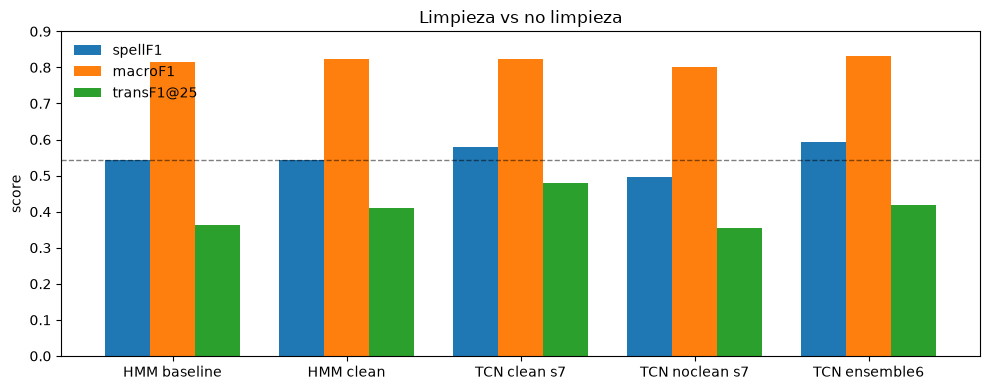

In [7]:
plot_df = pd.DataFrame({
    "HMM baseline": hmm.loc["HMM baseline (sin limpieza)", ["spellF1", "macroF1", "transF1@25"]],
    "HMM clean": hmm.loc["HMM clean", ["spellF1", "macroF1", "transF1@25"]],
    "TCN clean s7": tcn.loc["TCN clean seed7", ["spellF1", "macroF1", "transF1@25"]],
    "TCN noclean s7": tcn.loc["TCN noclean seed7", ["spellF1", "macroF1", "transF1@25"]],
    "TCN ensemble6": tcn.loc["TCN clean ensemble6", ["spellF1", "macroF1", "transF1@25"]],
}).T

ax = plot_df.plot(kind="bar", figsize=(10, 4), ylim=(0, 0.9), width=0.78)
ax.set_ylabel("score")
ax.set_title("Limpieza vs no limpieza")
ax.axhline(0.5444, color="black", linewidth=1, linestyle="--", alpha=0.5)
ax.legend(loc="upper left", frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Target final por frame

La submission final es `los_chuchos.csv` (id?ntica a `evaluation/results/model_tcn_clean.csv`). Aqu? se muestra la etiqueta de cada frame desde el inicio hasta el final del partido. El eje X est? en minutos y cada color representa una etiqueta: azul `H`, naranja `A`, gris `D` y gris claro `X`.


Target final: C:\Barcelona2026\more-than-a-hack-2027\los_chuchos.csv


,frames,pct
H,52068,26.12
A,37913,19.02
D,89031,44.67
X,20307,10.19


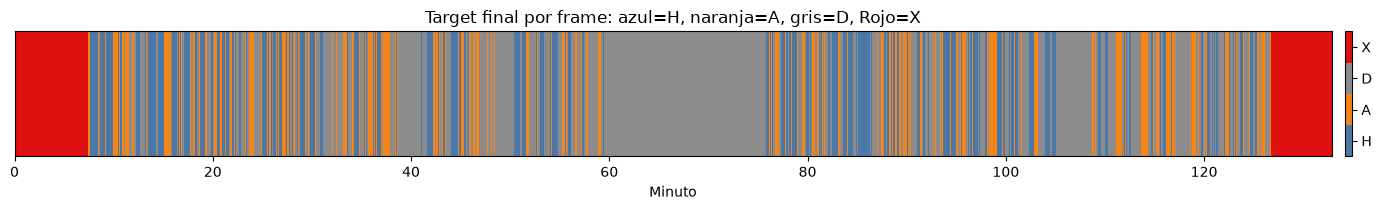

In [8]:
from matplotlib.colors import ListedColormap

final_path = ROOT / "los_chuchos.csv"
if not final_path.exists():
    final_path = ROOT / "evaluation" / "results" / "model_tcn_clean.csv"

final_codes = pm.label_codes(pm.read_label_csv(final_path))
final_counts = pd.Series(final_codes).value_counts().reindex(range(4), fill_value=0)
final_counts.index = list(pm.LABELS)

print("Target final:", final_path)
display(final_counts.rename("frames").to_frame().assign(
    pct=lambda frame: 100.0 * frame["frames"] / len(final_codes)
).round(2))

full_cmap = ListedColormap(["#4c78a8", "#f58518", "#8c8c8c", "#df1010"])
minutes = len(final_codes) / pm.FPS / 60.0

fig, ax = plt.subplots(figsize=(14, 2.2))
image = ax.imshow(
    final_codes[None, :],
    aspect="auto",
    interpolation="nearest",
    origin="lower",
    extent=[0, minutes, 0, 1],
    cmap=full_cmap,
    vmin=-0.5,
    vmax=3.5,
)
ax.set_yticks([])
ax.set_xlabel("Minuto")
ax.set_title("Target final por frame: azul=H, naranja=A, gris=D, Rojo=X")
cbar = fig.colorbar(image, ax=ax, ticks=[0, 1, 2, 3], pad=0.01, fraction=0.02)
cbar.ax.set_yticklabels(list(pm.LABELS))
plt.tight_layout()
plt.show()


### Target final recortado (frames 11185-190197)

La misma gráfica, pero eliminando los bloques de `X` del inicio y del final. El eje X sigue en minutos del partido.

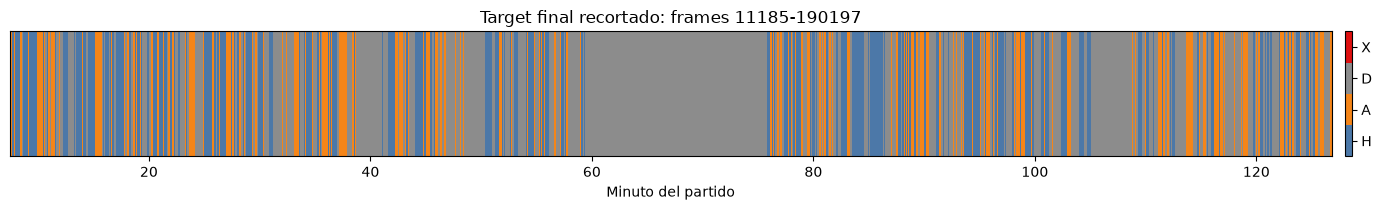

X frames en el recorte: 0


In [9]:
crop_start = 11185
crop_stop = 190197
crop_codes = final_codes[crop_start:crop_stop]
crop_start_min = crop_start / pm.FPS / 60.0
crop_stop_min = crop_stop / pm.FPS / 60.0

fig, ax = plt.subplots(figsize=(14, 2.2))
image = ax.imshow(
    crop_codes[None, :],
    aspect="auto",
    interpolation="nearest",
    origin="lower",
    extent=[crop_start_min, crop_stop_min, 0, 1],
    cmap=full_cmap,
    vmin=-0.5,
    vmax=3.5,
)
ax.set_yticks([])
ax.set_xlim(crop_start_min, crop_stop_min)
ax.set_xlabel("Minuto del partido")
ax.set_title("Target final recortado: frames 11185-190197")
cbar = fig.colorbar(image, ax=ax, ticks=[0, 1, 2, 3], pad=0.01, fraction=0.02)
cbar.ax.set_yticklabels(list(pm.LABELS))
plt.tight_layout()
plt.show()

print("X frames en el recorte: {}".format(int((crop_codes == pm.X).sum())))


### Conteo de X en el target final

Se cuentan los tramos contiguos de `X`. Un tramo que toca el frame 0 o el ?ltimo frame se considera inicio/final; el resto se considera ?en mitad? de la gr?fica.


In [10]:
x_mask = final_codes == pm.X
changes = np.diff(np.concatenate(([0], x_mask.astype(np.int8), [0])))
x_starts = np.flatnonzero(changes == 1)
x_ends = np.flatnonzero(changes == -1)

x_runs = pd.DataFrame({
    "start_frame": x_starts,
    "end_frame": x_ends - 1,
    "frames": x_ends - x_starts,
})
x_runs["start_min"] = x_runs["start_frame"] / pm.FPS / 60.0
x_runs["end_min"] = x_runs["end_frame"] / pm.FPS / 60.0
x_runs["position"] = np.where(
    x_runs["start_frame"] == 0,
    "inicio",
    np.where(x_runs["end_frame"] == len(final_codes) - 1, "final", "mitad"),
)

print("X total: {} frames ({:.2f}%)".format(
    int(x_mask.sum()), 100.0 * x_mask.mean()))
print("Tramos de X: {}".format(len(x_runs)))
display(x_runs.round(2))

middle = x_runs[x_runs["position"] == "mitad"]
print("Tramos de X en mitad: {}".format(len(middle)))
print("Frames de X en mitad: {}".format(int(middle["frames"].sum())))


X total: 20307 frames (10.19%)
Tramos de X: 2


,start_frame,end_frame,frames,start_min,end_min,position
0,0,11184,11185,0.0,7.46,inicio
1,190197,199318,9122,126.8,132.88,final


Tramos de X en mitad: 0
Frames de X en mitad: 0


## 4. Lectura

- **HMM**: `clean` y `noclean` dan el mismo `spellF1` (0.5444). El control reproduce exactamente el baseline, así que la comparación es válida. La limpieza sí cambia `macroF1` y `transF1@25` en el HMM limpio.
- **TCN seed 7**: con limpieza sube a `spellF1=0.5789`; sin limpieza cae a `0.4973`. La diferencia es `+0.0816` de `spellF1`, `+0.0210` de `macroF1` y `+0.1227` de `transF1@25`.
- **Cautela**: es una sola seed. Los intervalos bootstrap de `spellF1` se solapan (`[0.4316, 0.7158]` vs `[0.3459, 0.6595]`), así que no es una diferencia estadísticamente concluyente.
- **Referencia**: el ensemble de 6 TCN limpios llega a `0.5943`; no es comparable 1-a-1 con las seed 7, pero sitúa la magnitud final.
- Con este control, la limpieza **sí parece aportar** al TCN, sobre todo en transiciones y estructura de posesiones. No era visible en el HMM porque el HMM no usa `ball_x`, `ball_y`, `last_seen` ni las features de hueco.


## 5. Reproducir

```powershell
# 1) Control sin limpieza
python models/ball_clean_ensemble/build_features_noclean.py

# 2) HMM de control
python models/ball_clean_ensemble/run_clean_pipelines.py `
  --skip-baseline `
  --clean-features models/ball_clean_ensemble/features_noclean.npz `
  --rawmissing-features models/ball_clean_ensemble/features_noclean.npz `
  --centroidref-features models/ball_clean_ensemble/features_noclean.npz `
  --results-dir models/ball_clean_ensemble/results_noclean

# 3) TCN sin limpieza (seed 7)
python models/ball_clean_ensemble/train_tcn_clean.py `
  --seed 7 --tag noclean `
  --features models/ball_clean_ensemble/features_noclean.npz `
  --labels models/ball_clean_ensemble/results_noclean/clean_ensemble.csv `
  --skip-variants

# 4) Decodificar TCN sin limpieza
python models/ball_clean_ensemble/run_tcn_variants.py `
  --logits models/ball_clean_ensemble/tcn_clean_logits_noclean.npz `
  --features models/ball_clean_ensemble/features_noclean.npz `
  --prefix noclean_

# 5) Decodificar TCN limpio seed 7 para comparación 1-a-1
python models/ball_clean_ensemble/run_tcn_variants.py `
  --logits models/ball_clean_ensemble/tcn_clean_logits.npz `
  --features models/ball_clean_ensemble/features_clean_long_lastseen.npz `
  --prefix clean_seed7_
```


## 6. Limitaciones

- Una seed por rama. Para una conclusión fuerte habría que repetir con las 6 seeds y comparar los ensembles.
- El control sin limpieza también cambia las pseudoetiquetas HMM, porque se generan con sus propias features. Es una ablación de pipeline completo, no solo de un canal.
- El GT público tiene 17 posesiones; los intervalos bootstrap son anchos.
